In [235]:
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_recall_curve,
                             average_precision_score, classification_report)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight

import pandas as pd
import preprocessing as pp
import encoding as enc
import matplotlib.pyplot as plt
import seaborn as sns
import graphviz


In [236]:


raw = pp.load_raw()
df = pp.clean(raw)

pp.cleaning_report(raw, df)

,rows,columns,duplicate rows,cells missing,text columns
raw,2930,82,0,719,43
cleaned,2930,77,0,649,39


In [237]:
target = enc.make_target(df)


class_counts = target.value_counts().sort_index()

class_percentages = (
    target
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage": class_percentages.round(2)
})

display(class_distribution)

y = enc.make_target(df)

X = df.drop(columns=['SalePrice', 'Price Class'], errors='ignore')

X = enc.encode_features(X)



,Count,Percentage
SalePrice,,
0,237,8.09
1,509,17.37
2,1037,35.39
3,686,23.41
4,397,13.55
5,64,2.18


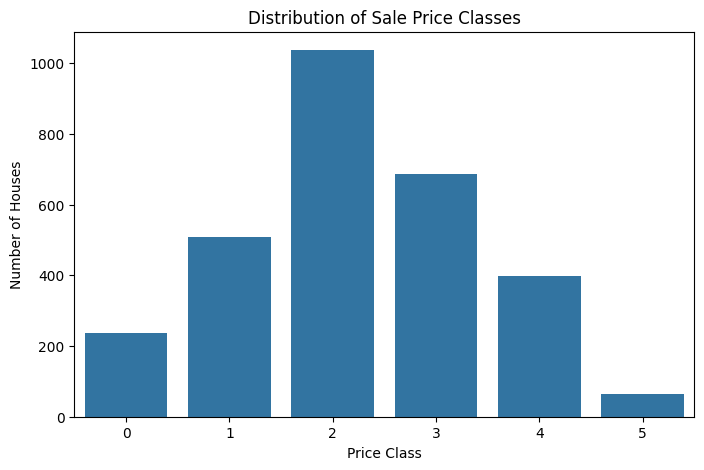

In [238]:
plt.figure(figsize=(8, 5))

sns.countplot(x=target)

plt.title("Distribution of Sale Price Classes")
plt.xlabel("Price Class")
plt.ylabel("Number of Houses")

plt.show()

In [239]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [240]:
print(X_train.shape)
print(X_test.shape)

X_train.head()


(2344, 222)
(586, 222)


,Lot Frontage,Lot Area,Lot Shape,Land Slope,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,Exter Qual,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
2354,81.0,10530,0.0,0.0,6,6,1975,2000,248.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1621,NaN,10147,1.0,0.0,6,5,1994,1994,32.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1155,95.0,19508,0.0,0.0,6,5,1974,1974,144.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2674,65.0,7800,0.0,0.0,5,7,1939,1950,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1343,NaN,6120,0.0,0.0,5,6,1945,1995,0.0,3.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [241]:
missing = X_train.isnull().sum()
display(missing[missing > 0].sort_values(ascending=False).head(20))

Lot Frontage     399
Garage Yr Blt    123
dtype: int64

In [242]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='median')

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

In [243]:
print("Missing values in training:", X_train.isnull().sum().sum())
print("Missing values in testing:", X_test.isnull().sum().sum())

Missing values in training: 0
Missing values in testing: 0


In [244]:
xgb_model = XGBClassifier(
    objective='multi:softprob',
    num_class=6,
    eval_metric='mlogloss',
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    tree_method='hist'
)

In [245]:
xgb_model.fit(X_train, y_train)

,"objective objective: typing.Union[str, xgboost.objective.Objective, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets impo

In [246]:
y_pred = xgb_model.predict(X_test)

y_prob = xgb_model.predict_proba(X_test)

In [247]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Recall:", recall_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("Macro F1:", f1_score(
    y_test, y_pred, average='macro', zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

Accuracy: 0.7713310580204779
Precision: 0.7678737093431777
Recall: 0.7173302691172422
Macro F1: 0.7380310010878772

Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.67      0.70        48
           1       0.70      0.68      0.69       102
           2       0.78      0.86      0.81       207
           3       0.81      0.74      0.78       137
           4       0.80      0.82      0.81        79
           5       0.78      0.54      0.64        13

    accuracy                           0.77       586
   macro avg       0.77      0.72      0.74       586
weighted avg       0.77      0.77      0.77       586



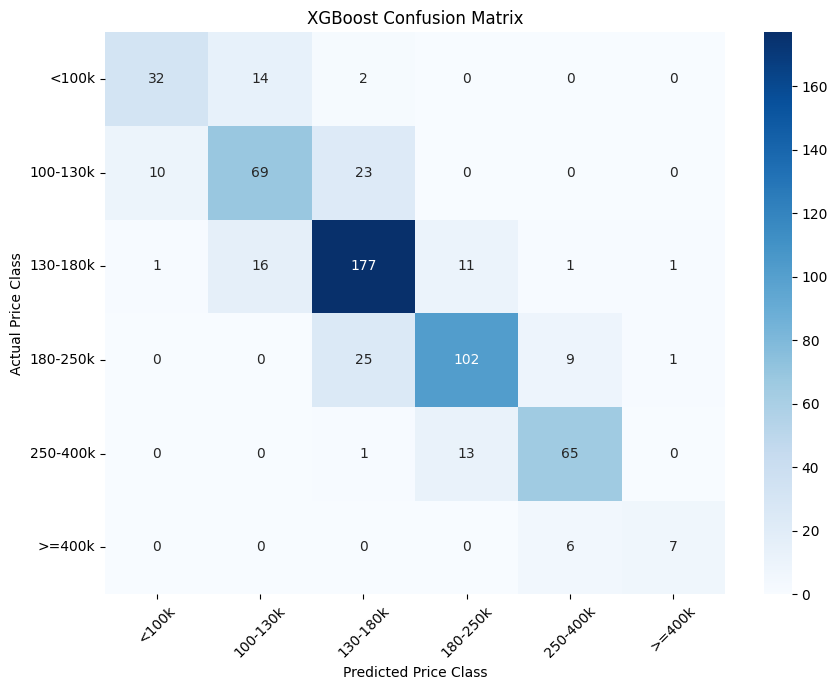

In [248]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=enc.price_labels,
    yticklabels=enc.price_labels
)

plt.xlabel("Predicted Price Class")
plt.ylabel("Actual Price Class")
plt.title("XGBoost Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [249]:
import numpy as np
import xgboost as xgb
import optuna

from sklearn.model_selection import cross_validate
from sklearn.impute import SimpleImputer

In [250]:
def make_data(drop_low_variance=True):
    # load -> clean -> encode, returns X and the 6 price classes
    df = pp.clean(pp.load_raw(), drop_low_variance=drop_low_variance)
    y = enc.make_target(df)
    X = enc.encode_features(df.drop(columns=enc.target_cols, errors='ignore'))
    return X, y


def impute(X_train, X_test):
    # median imputation fitted only on the training fold
    imp = SimpleImputer(strategy='median')
    X_train = pd.DataFrame(imp.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test = pd.DataFrame(imp.transform(X_test), columns=X_test.columns, index=X_test.index)
    return X_train, X_test


def make_model(**params):
    # baseline parameters, can be overridden one by one
    base = dict(
        objective='multi:softprob',
        num_class=enc.n_classes,
        eval_metric='mlogloss',
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        tree_method='hist'
    )
    base.update(params)
    return XGBClassifier(**base)


X, y = make_data()
print(X.shape, y.value_counts().sort_index().to_dict())

(2930, 222) {0: 237, 1: 509, 2: 1037, 3: 686, 4: 397, 5: 64}


In [251]:
def run_split(X, y, test_size, stratify):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=42,
        stratify=y if stratify else None
    )
    X_tr, X_te = impute(X_tr, X_te)

    model = make_model()
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)

    return {
        'test_size': test_size,
        'stratify': stratify,
        'accuracy': accuracy_score(y_te, pred),
        'macro_f1': f1_score(y_te, pred, average='macro', zero_division=0),
        'smallest_class_in_test': y_te.value_counts().min()
    }


results = [run_split(X, y, ts, st) for ts in (0.1, 0.2) for st in (False, True)]
split_results = pd.DataFrame(results)
display(split_results)

,test_size,stratify,accuracy,macro_f1,smallest_class_in_test
0,0.1,False,0.774744,0.723039,10
1,0.1,True,0.767918,0.766706,6
2,0.2,False,0.767918,0.724519,20
3,0.2,True,0.771331,0.738031,13


we can observe an improvement in our macro f1 above using stratification. this is because we are making our classes proportional

In [252]:
def run_cv(X, y, k, model=None):
    X_imp = pd.DataFrame(
        SimpleImputer(strategy='median').fit_transform(X),
        columns=X.columns
    )
    cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

    scores = cross_validate(
        model if model is not None else make_model(),
        X_imp, y, cv=cv, scoring='f1_macro',
        return_train_score=True, n_jobs=-1
    )

    return {
        'k': k,
        'train_f1': scores['train_score'].mean(),
        'val_f1': scores['test_score'].mean(),
        'val_std': scores['test_score'].std(),
        'gap': scores['train_score'].mean() - scores['test_score'].mean()
    }


cv_results = pd.DataFrame([run_cv(X, y, 5), run_cv(X, y, 10)])
display(cv_results)

,k,train_f1,val_f1,val_std,gap
0,5,0.987707,0.734441,0.014519,0.253266
1,10,0.983789,0.745924,0.041205,0.237865


gap is train_f1 - val_f1, which directly measures overfitting.

val_std measures variation between folds. with k=10 we have less folds meaning that scores are all over the place. with k=5 the prediction is more stable, but more pessimistic


In [253]:
def run_weighting(X, y, mode):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )
    X_tr, X_te = impute(X_tr, X_te)

    w = None
    if mode == 'balanced':
        w = compute_sample_weight('balanced', y_tr)
    elif mode == 'sqrt':
        # softer version of balanced weights
        w = np.sqrt(compute_sample_weight('balanced', y_tr))

    model = make_model()
    model.fit(X_tr, y_tr, sample_weight=w)
    pred = model.predict(X_te)

    row = {
        'mode': mode,
        'accuracy': accuracy_score(y_te, pred),
        'macro_f1': f1_score(y_te, pred, average='macro', zero_division=0)
    }
    # recall per class, to see what happens with the rare ones
    rec = recall_score(y_te, pred, average=None, zero_division=0)
    for i, r in enumerate(rec):
        row[f'recall_{i}'] = round(r, 3)
    return row


weight_results = pd.DataFrame([run_weighting(X, y, m) for m in ('none', 'sqrt', 'balanced')])
display(weight_results)

,mode,accuracy,macro_f1,recall_0,recall_1,recall_2,recall_3,recall_4,recall_5
0,none,0.771331,0.738031,0.667,0.676,0.855,0.745,0.823,0.538
1,sqrt,0.773038,0.755689,0.729,0.716,0.826,0.737,0.823,0.615
2,balanced,0.755973,0.733771,0.729,0.745,0.763,0.737,0.823,0.615


"balanced" gives each class an inversely proportional to its frequency (for example class 5 has a weight way larger than class 2)

the consequence is that recall grows for rare classes and slightly reduces global accuracy, since the model starts to force predictions to smaller classes

"sqrt" is a compromise that maintains the direction of the correction but with a smaller amplitude

We choose the variant with the best macro_f1 (compute_sample_weight doesnt have sqrt)

In [254]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_tr, X_te = impute(X_tr, X_te)

w_tr = compute_sample_weight(None,y_tr)

model = make_model()
model.fit(X_tr, y_tr, sample_weight=w_tr)

y_pred = model.predict(X_te)
y_prob = model.predict_proba(X_te)

print("Accuracy:", accuracy_score(y_te, y_pred))
print("Precision:", precision_score(y_te, y_pred, average='macro', zero_division=0))
print("Recall:", recall_score(y_te, y_pred, average='macro', zero_division=0))
print("Macro F1:", f1_score(y_te, y_pred, average='macro', zero_division=0))
print()
print(classification_report(y_te, y_pred, target_names=enc.price_labels, zero_division=0))

Accuracy: 0.7713310580204779
Precision: 0.7678737093431777
Recall: 0.7173302691172422
Macro F1: 0.7380310010878772

              precision    recall  f1-score   support

       <100k       0.74      0.67      0.70        48
    100-130k       0.70      0.68      0.69       102
    130-180k       0.78      0.86      0.81       207
    180-250k       0.81      0.74      0.78       137
    250-400k       0.80      0.82      0.81        79
      >=400k       0.78      0.54      0.64        13

    accuracy                           0.77       586
   macro avg       0.77      0.72      0.74       586
weighted avg       0.77      0.77      0.77       586



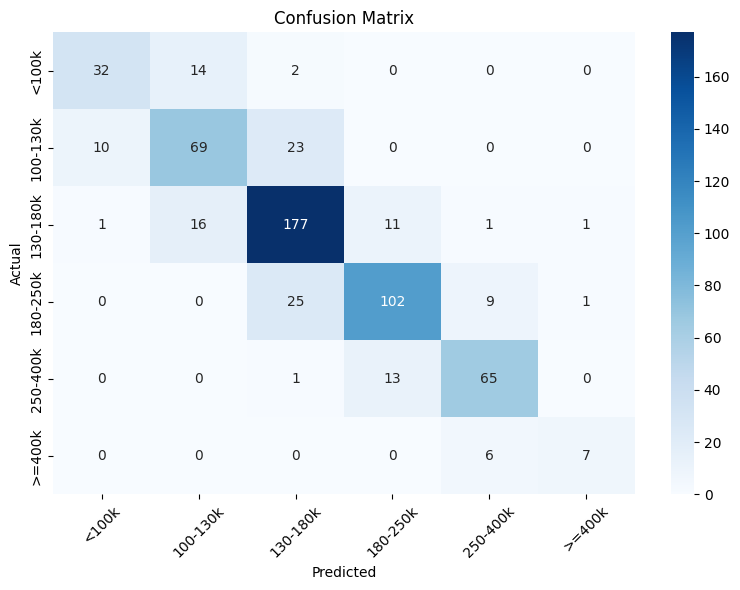

In [255]:
cm = confusion_matrix(y_te, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=enc.price_labels, yticklabels=enc.price_labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

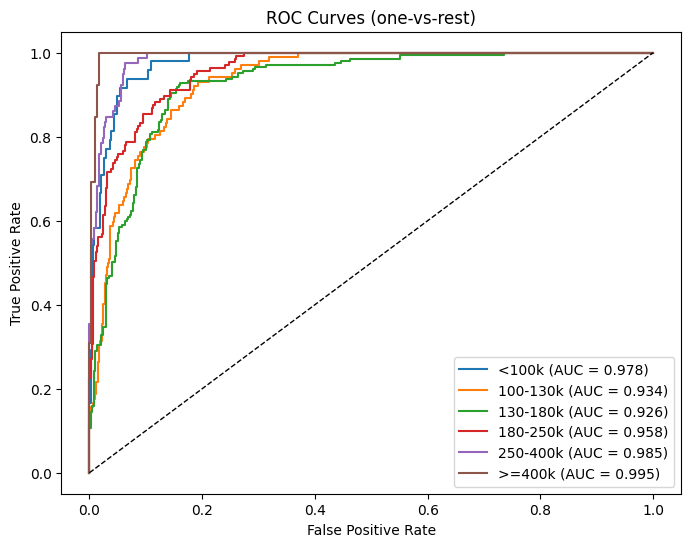

Macro AUC: 0.962758784809763


In [256]:
y_te_bin = label_binarize(y_te, classes=range(enc.n_classes))

plt.figure(figsize=(8, 6))
for i in range(enc.n_classes):
    fpr, tpr, _ = roc_curve(y_te_bin[:, i], y_prob[:, i])
    auc = roc_auc_score(y_te_bin[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, label=f"{enc.price_labels[i]} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves (one-vs-rest)")
plt.legend()
plt.show()

print("Macro AUC:", roc_auc_score(y_te_bin, y_prob, average='macro', multi_class='ovr'))

the AUC values look high for every class, including the rare ones. this is because ethe data is imbalanced


the precision-recall curves are the better version. average precision drops
clearly for the small classes, because precision is computed only from the
predicted positives and there are only a  few of.

for our problem the PR curves describe the model much better than the ROC ones.

In [257]:
def best_thresholds(y_bin, y_prob):
    # for each class, pick the threshold with the best one-vs-rest f1
    thresholds = []
    for i in range(y_prob.shape[1]):
        prec, rec, thr = precision_recall_curve(y_bin[:, i], y_prob[:, i])
        f1 = 2 * prec * rec / (prec + rec + 1e-9)
        # last point of the curve has no threshold
        best = f1[:-1].argmax()
        thresholds.append(thr[best])
    return np.array(thresholds)


thr = best_thresholds(y_te_bin, y_prob)

# rescale probabilities by the thresholds, then take the argmax
y_pred_thr = (y_prob / thr).argmax(axis=1)

print("Thresholds:", dict(zip(enc.price_labels, thr.round(3))))
print()
print("Macro F1 (argmax):    ", f1_score(y_te, y_pred, average='macro', zero_division=0))
print("Macro F1 (thresholds):", f1_score(y_te, y_pred_thr, average='macro', zero_division=0))
print()
print(classification_report(y_te, y_pred_thr, target_names=enc.price_labels, zero_division=0))

Thresholds: {'<100k': np.float32(0.145), '100-130k': np.float32(0.402), '130-180k': np.float32(0.359), '180-250k': np.float32(0.404), '250-400k': np.float32(0.459), '>=400k': np.float32(0.263)}

Macro F1 (argmax):     0.7380310010878772
Macro F1 (thresholds): 0.7505842479388253

              precision    recall  f1-score   support

       <100k       0.66      0.77      0.71        48
    100-130k       0.73      0.61      0.66       102
    130-180k       0.78      0.87      0.82       207
    180-250k       0.82      0.75      0.78       137
    250-400k       0.83      0.82      0.83        79
      >=400k       0.80      0.62      0.70        13

    accuracy                           0.78       586
   macro avg       0.77      0.74      0.75       586
weighted avg       0.78      0.78      0.77       586



"predict" takes the class with the highest probability, meaning that it uses a threshold of 1/6 for every class. picking the threshold that maximises
the one-vs-rest f1 per class and then dividing the probabilities by it, rare classes need less confidence to be chosen

as expected, the thresholds are lower for the small classes

In [258]:
import os

os.environ["PATH"] += os.pathsep + r'C:\Program Files (x86)\Graphviz\bin'

c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


<Figure size 2000x1000 with 0 Axes>

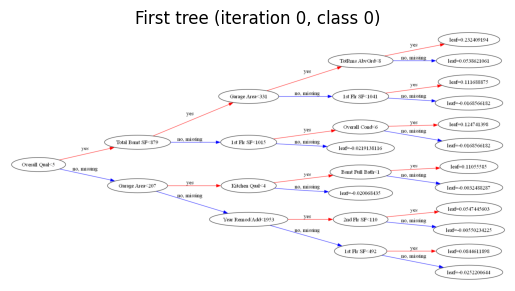

In [259]:
# in a multiclass model, tree index = iteration * n_classes + class
plt.figure(figsize=(20, 10))
xgb.plot_tree(model, num_trees=0, rankdir='LR')
plt.title("First tree (iteration 0, class 0)")
plt.show()

Best iteration: 374
Macro F1: 0.7389028183935737


c:\Users\shoml\AppData\Local\Programs\Python\Python312\Lib\site-packages\xgboost\plotting.py:268: FutureWarning: The `num_trees` parameter is deprecated, use `tree_idx` instead. 
  warnings.warn(


<Figure size 2000x1000 with 0 Axes>

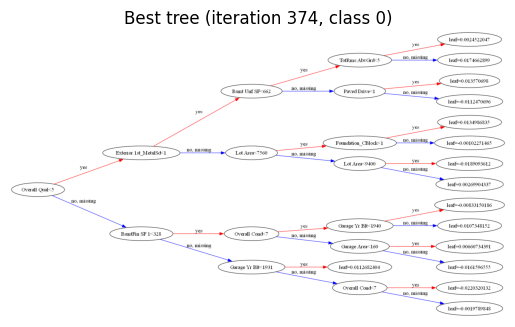

In [260]:
# retrain with early stopping to find the best iteration
es_model = make_model(n_estimators=1000, early_stopping_rounds=30)
es_model.fit(X_tr, y_tr, sample_weight=w_tr, eval_set=[(X_te, y_te)], verbose=False)

print("Best iteration:", es_model.best_iteration)
print("Macro F1:", f1_score(y_te, es_model.predict(X_te), average='macro', zero_division=0))

plt.figure(figsize=(20, 10))
xgb.plot_tree(es_model, num_trees=es_model.best_iteration * enc.n_classes, rankdir='LR')
plt.title(f"Best tree (iteration {es_model.best_iteration}, class 0)")
plt.show()

thee first tree splits on the strongest global signals (for example overall quality and living area). its leaf values are large, because it has to move the prediction away from the initial guess

the tree at the best iteration looks different: it splits on narrower features and its leaf values are much smaller. by then most of the signal is already captured, so each new tree only corrects the residual errors

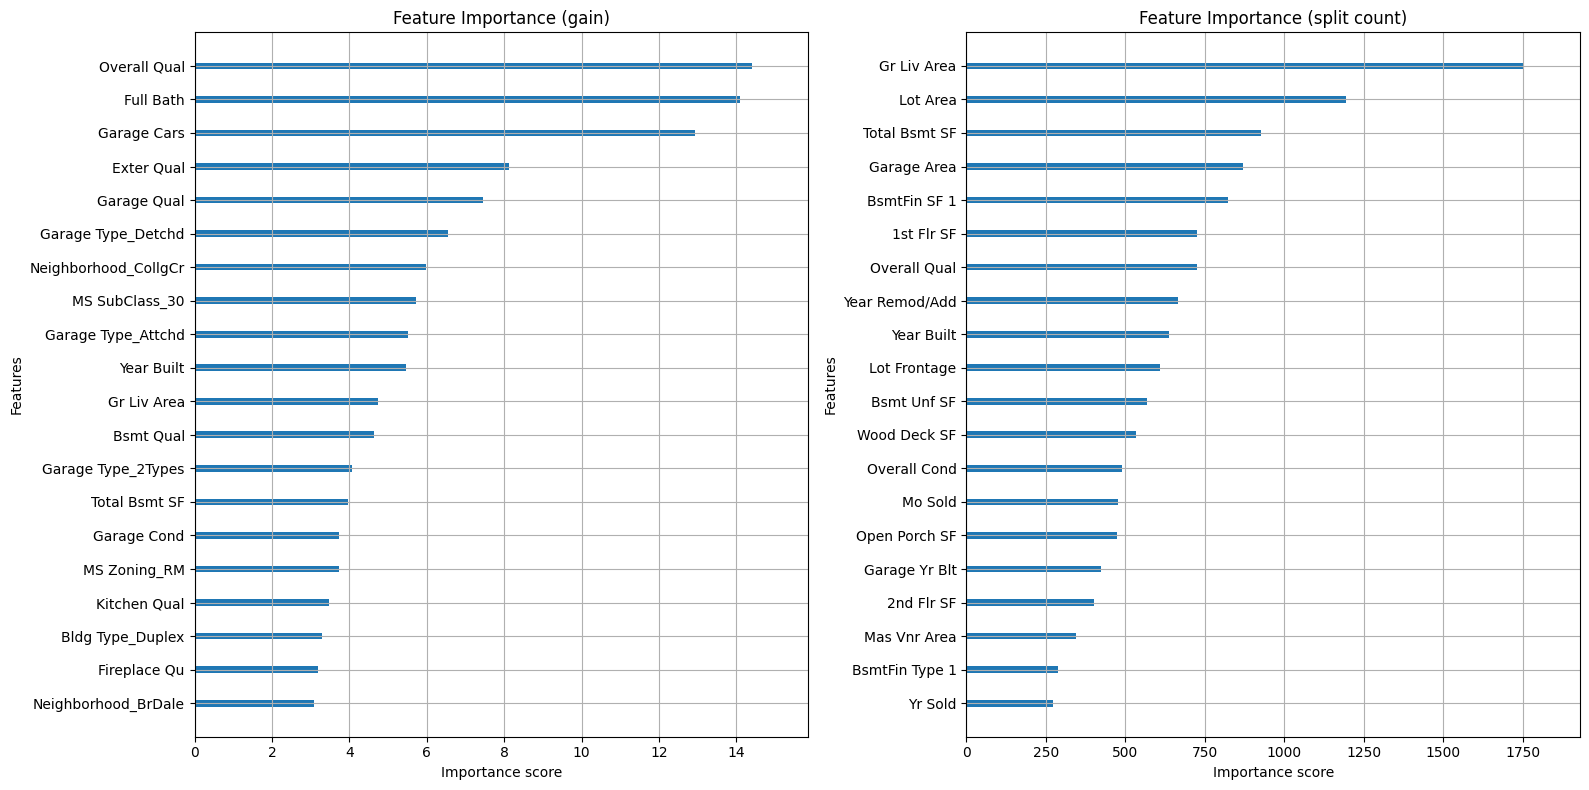

In [261]:
fig, ax = plt.subplots(1, 2, figsize=(16, 8))

xgb.plot_importance(model, importance_type='gain', max_num_features=20,
                    ax=ax[0], title="Feature Importance (gain)", show_values=False)
xgb.plot_importance(model, importance_type='weight', max_num_features=20,
                    ax=ax[1], title="Feature Importance (split count)", show_values=False)

plt.tight_layout()
plt.show()

gain - how much each feature reduced the loss when it was used. a feature used only a few times but in decisive splits scores high here

split count - how often the feature was used. for example, Gr. Liv Area is high because there are many possible cut points

the one-hot columns are the clearest case: a neighbourhood like "StoneBr" is rarely used, but it separates expensive houses very well

for explaining what actually increases the price, gain is the more useful view

In [262]:
def add_features(df):
    # extra features built from existing columns
    df = df.copy()
    df['House Age'] = df['Yr Sold'] - df['Year Built']
    df['Remod Age'] = df['Yr Sold'] - df['Year Remod/Add']
    df['Was Remodeled'] = (df['Year Remod/Add'] != df['Year Built']).astype(int)
    df['Total Baths'] = (df['Full Bath'] + 0.5 * df['Half Bath']
                         + df['Bsmt Full Bath'] + 0.5 * df['Bsmt Half Bath'])
    df['Total SF'] = df['Total Bsmt SF'] + df['Gr Liv Area']
    df['Has Pool'] = (df['Pool Area'] > 0).astype(int)
    return df


def make_data_v2(drop_low_variance=True, features=False, drop_redundant=False):
    # same as make_data, with optional feature engineering
    df = pp.clean(pp.load_raw(), drop_low_variance=drop_low_variance)
    if features:
        df = add_features(df)
    y = enc.make_target(df)
    X = df.drop(columns=enc.target_cols, errors='ignore')
    if drop_redundant:
        # Garage Yr Blt is almost the same as Year Built (see the heatmap)
        X = X.drop(columns=['Garage Yr Blt'], errors='ignore')
    return enc.encode_features(X), y

In [263]:
def eval_strategy(name, X, y, use_nan=False):
    # macro-f1 on a stratified 5-fold, same model everywhere
    X_in = X if use_nan else pd.DataFrame(
        SimpleImputer(strategy='median').fit_transform(X), columns=X.columns
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    scores = cross_validate(make_model(), X_in, y, cv=cv,
                            scoring='f1_macro', n_jobs=-1)
    return {
        'strategy': name,
        'n_features': X.shape[1],
        'macro_f1': scores['test_score'].mean(),
        'std': scores['test_score'].std()
    }



strategies = []

Xa, ya = make_data_v2()
strategies.append(eval_strategy('baseline (median impute)', Xa, ya))
strategies.append(eval_strategy('native NaN handling', Xa, ya, use_nan=True))

Xb, yb = make_data_v2(drop_low_variance=False)
strategies.append(eval_strategy('keep low variance cols', Xb, yb))

Xc, yc = make_data_v2(features=True)
strategies.append(eval_strategy('with new features', Xc, yc))

Xd, yd = make_data_v2(features=True, drop_redundant=True)
strategies.append(eval_strategy('features, no Garage Yr Blt', Xd, yd))

strategy_results = pd.DataFrame(strategies).sort_values('macro_f1', ascending=False)
display(strategy_results)

,strategy,n_features,macro_f1,std
3,with new features,228,0.738939,0.018338
1,native NaN handling,222,0.738416,0.011851
4,"features, no Garage Yr Blt",227,0.736446,0.008175
2,keep low variance cols,247,0.735931,0.008729
0,baseline (median impute),222,0.734441,0.014519
